In [ ]:
"""
激活函数  为了使模型变得更强
了解几个常用的激活函数
对数据进行转换 将输出变量从线性结构变成非线性结构
常见的激活函数有：
sigmoid: 一般用于输出层二分类的问题
    可以做逻辑回归
    sigmoid可以将任意的输入映射到(0,1)
    当数值在(-6,6)之外时整体影响不大 
    要获得较好的转换效果输入最好在(-3,3)之间
    会产生梯度消失
tanh 激活函数：
    将任意的输入映射到(-1,1) 图像以0为中心
    要获得较好的转换效果输入最好在(-3,3)之间
    不会产生梯度消失 因为导数的最大值为1
    收敛速度更快 因为梯度变化更快
    隐藏层使用tanh 输出层用sigmoid
ReLU 激活函数：
    将任意的输入映射到(0,正无穷)
    当数值在(-6,6)之外时整体影响不大
    不会产生梯度消失 因为没有梯度衰减的现象
    有的数据的权重为零 造成网络的稀疏性 缓解了过拟合
    一般使用ReLU
    大多数用于隐藏层
softmax 激活函数：
    将任意的输入映射到(0,1) 并且和为1
    选取概率最大的那个作为分类
    可以做多分类问题
    输出层使用softmax 隐藏层使用tanh 少使用sigmoid函数
"""

'\n激活函数  为了使模型变得更强\n对数据进行转换 将输出变量从线性结构变成非线性结构\n常见的激活函数有：\nsigmoid: 一般用于二分类的问题\n    可以做逻辑回归\n    sigmoid可以将任意的输入映射到(0,1)\n    当数值在(-6,6)之外时整体影响不大 \n    要获得较好的转换效果输入最好在(-3,3)之间\n    会产生梯度消失\n'

In [3]:
import torch
import matplotlib.pyplot as plt
import matplotlib
# 设置中文字体
matplotlib.rcParams['font.sans-serif'] = ['SimHei']   
matplotlib.rcParams['axes.unicode_minus'] = False     

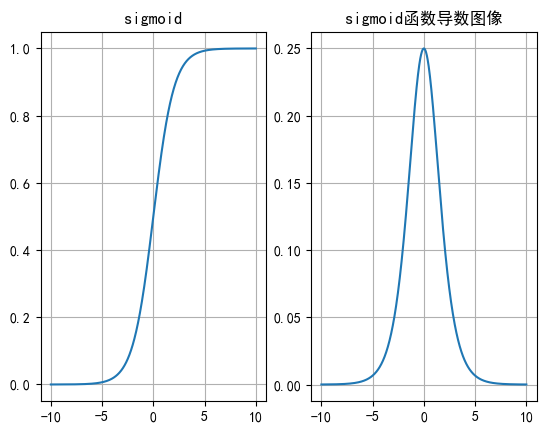

In [ ]:

# sigmoid 函数
# 创建画布
_,axes = plt.subplots(1,2) 
# 创建了一个线性张量
x = torch.linspace(-10,10,1000,requires_grad=True)
# 对输出层的数据进行sigmoid 函数处理
y = torch.sigmoid(x.detach())
axes[0].plot(x.detach(),y)
axes[0].grid()
axes[0].set_title('sigmoid')
# 绘制导数图像
# 反向传播得梯度或者导数值
torch.sigmoid(x).sum().backward()
# 绘制函数图像
axes[1].plot(x.detach(),x.grad)
axes[1].grid(True)
axes[1].set_title('sigmoid函数导数图像')
plt.show()

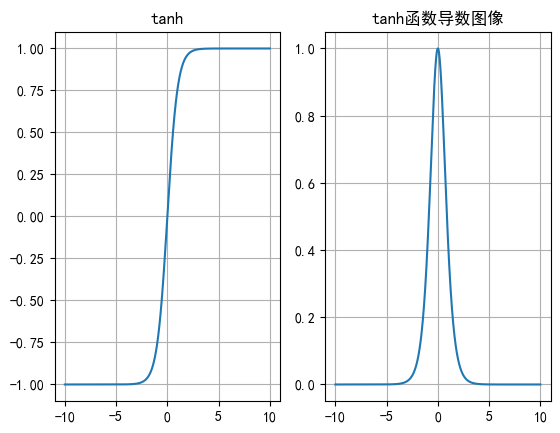

In [ ]:
# tanh 函数
# 创建画布
_,axes = plt.subplots(1,2) 
# 创建了一个线性张量 选择requires_grad=True后x的内存不再连续 画图的时候需要带上.detach() 否则会报错
x = torch.linspace(-10,10,1000,requires_grad=True)
y = torch.tanh(x.detach())
axes[0].plot(x.detach(),y)
axes[0].grid()
axes[0].set_title('tanh')
# 绘制导数图像
# 反向传播计算梯度
torch.tanh(x).sum().backward()
# 绘制函数图像
axes[1].plot(x.detach(),x.grad)
axes[1].grid(True)
axes[1].set_title('tanh函数导数图像')
plt.show()

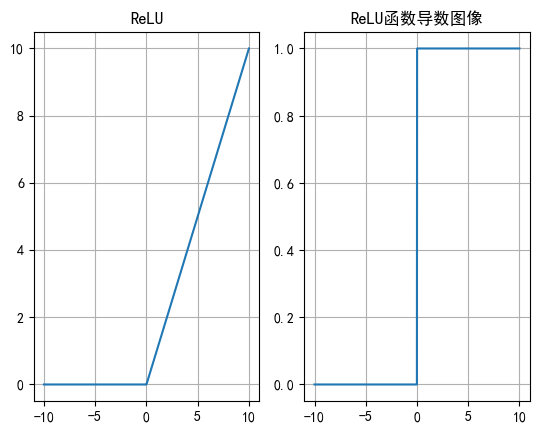

In [34]:

# ReLU 函数
# 创建画布
_,axes = plt.subplots(1,2) 
# 创建了一个线性张量
x = torch.linspace(-10,10,1000,requires_grad=True)
# 对输出层的数据进行sigmoid 函数处理
y = torch.relu(x.detach())
axes[0].plot(x.detach(),y)
axes[0].grid()
axes[0].set_title('ReLU')
# 绘制导数图像
# 反向传播得梯度或者导数值
torch.relu(x).sum().backward()
# 绘制函数图像
axes[1].plot(x.detach(),x.grad)
axes[1].grid(True)
axes[1].set_title('ReLU函数导数图像')
plt.show()

In [38]:
# Softmax函数
# 模拟加权求和
score = torch.tensor([0.13,4.68,0.3,0.4,-0.45])
# 转换为概率
probs = torch.softmax(score,dim=0)
print(probs)
score1 = torch.tensor([[0.1,0.2,-0.3],[1,-2,3]])
probs_0 =  torch.softmax(score1,dim=0)
probs_1 =  torch.softmax(score1,dim=1) 
print(f"probs_0:\n{probs_0}")
print(f"probs_1:\n{probs_1}")

tensor([0.0101, 0.9589, 0.0120, 0.0133, 0.0057])
probs_0:
tensor([[0.2891, 0.9002, 0.0356],
        [0.7109, 0.0998, 0.9644]])
probs_1:
tensor([[0.3603, 0.3982, 0.2415],
        [0.1185, 0.0059, 0.8756]])


In [ ]:
"""
案例:
    演示 深度学习中 参数初始化的操作.


参数初始化介绍:
    背景:
        例如Tanh激活函数, 导数最大值为1, 我们可以调整线性公式y = wx + b中的 w,b的值
	    从而使得函数的求导结果接近1, 这样就达到了激活函数的最优效果.
	作用:
	    1.防止梯度消失或者梯度爆炸.
	    2.提高收敛速度.
	    3.保持对称性打破.

	常用的参数初始化介绍:
	    1. 随机初始化 -> 从均值为0, 标准差为1的高斯分布中取样.
	        优点: 能有效打破对称性, 保持数据均衡.
	        缺点: 随机选择范围不当, 可能导致梯度问题.
	        适用场景: 浅层网络 或者 低复杂度模型,  隐藏层1~3层, 总层数不超过5层.
	    2. 全0初始化 -> 将神经网络中所有权重参数初始化为0.
	        优点: 实现简单.
	        缺点: 无法打破对称性, 所有神经元更新方向相同, 无法有效训练.
	        使用场景: 几乎不用, 仅用于 偏置项的初始化, 即: bias设置为0
	    3. 全1初始化 -> 将神经网络中所有权重参数初始化为1.
	        优点: 实现简单.
	        缺点: 无法打破对称性, 所有神经元更新方向相同, 训练效果差.  容易梯度爆炸.
	        使用场景: 测试和调试.
	    4. 固定值初始化 -> 将神经网络中所有权重参数初始化为固定值.
	        优点: 实现简单.
	        缺点:
	            无法打破对称性, 所有神经元更新方向相同, 训练效果差.
	            初始权重过大 或者 过小都可能导致 梯度爆炸或梯度消失.
	        使用场景:
	            测试或者调试.
	    5. kaiming初始化 -> 也叫HE初始化.
	        优点: 适合ReLU, 能保持梯度稳定.
	        缺点: 对非ReLU激活函数效果一般.
	        使用场景: 深层网络(10层及以上), 使用ReLU, Leaky ReLU激活函数.
	    6. xavier初始化 -> 也叫Glorot初始化.
	        优点: 使用Sigmoid, Tanh等激活函数, 解决梯度消失的问题.
	        缺点: 对ReLU等激活函数效果欠佳.
	        使用场景: 深层网络(10层及以上), 使用Sigmoid, Tanh等激活函数.

    如何选择参数初始化:
        思路1: 激活函数的选择.
            如果用Sigmoid/Tanh:    建议使用 xavier 初始化.
            如果是ReLU/Leaky ReLU: 建议使用 kaiming初始化
        思路2: 神经网络模型的深度
            浅层网络: 随机初始化即可.
            深层网络: 需要考虑方差平衡, 用xavier 或者 kaiming初始化.

"""

In [2]:
# 导包
import torch.nn as nn                               # 神经网络模块
import torch.nn.functional as F                     # 激活函数模块

In [13]:
# 均值初始化
# 输入三个特征 输出五个特征
linear = nn.Linear(3,5)             # 定义输入输出层
# 0,1均值初始化 linear.weight是模型权重 linear.bais是模型偏置
print(linear.weight.data)
nn.init.uniform_(linear.weight)
nn.init.uniform_(linear.bias)
print(linear.weight.data)
print(linear.bias.data)

tensor([[-0.1843, -0.4249, -0.2684],
        [-0.2288,  0.3965,  0.2654],
        [ 0.2327, -0.5615, -0.1585],
        [ 0.3741,  0.4631, -0.3489],
        [-0.3042,  0.3657,  0.5722]])
tensor([[0.1624, 0.7608, 0.6389],
        [0.8510, 0.5990, 0.3677],
        [0.1832, 0.9053, 0.3225],
        [0.4837, 0.6887, 0.0369],
        [0.1070, 0.7899, 0.8702]])
tensor([0.1762, 0.1395, 0.8843, 0.5024, 0.4085])


In [5]:
# 固定值初始化
linear = nn.Linear(3,5)             # 定义输入输出层
nn.init.constant_(linear.weight,2)
print(linear.weight.data)


tensor([[2., 2., 2.],
        [2., 2., 2.],
        [2., 2., 2.],
        [2., 2., 2.],
        [2., 2., 2.]])


In [8]:
# 全0和全1初始化
linear = nn.Linear(3,5)             # 定义输入输出层
nn.init.zeros_(linear.weight)
print(linear.weight.data)
nn.init.ones_(linear.weight)
print(linear.weight.data)

tensor([[0., 0., 0.],
        [0., 0., 0.],
        [0., 0., 0.],
        [0., 0., 0.],
        [0., 0., 0.]])
tensor([[1., 1., 1.],
        [1., 1., 1.],
        [1., 1., 1.],
        [1., 1., 1.],
        [1., 1., 1.]])


In [10]:
# 正态初始化
linear = nn.Linear(3,5)             # 定义输入输出层
nn.init.normal_(linear.weight)
nn.init.normal_(linear.bias)
print(linear.weight.data)
print(linear.bias.data)

tensor([[-0.2985,  0.9031, -0.7959],
        [-0.7158,  0.0538,  1.7355],
        [-0.7381, -1.0987,  0.2943],
        [ 0.7127,  0.1212,  0.2896],
        [ 0.2709,  0.1953,  0.9235]])
tensor([ 0.0177, -1.9752, -0.2544,  0.2118,  0.6920])


In [11]:
# kaiming初始化
linear = nn.Linear(3,5)
# kaiming正态初始化
nn.init.kaiming_normal_(linear.weight)
print(linear.weight.data)
# kaiming均匀初始化
nn.init.kaiming_uniform_(linear.weight)
print(linear.weight.data)

tensor([[ 1.3772, -0.3539, -0.3105],
        [-1.9331, -0.1387,  0.0747],
        [-0.1097,  0.5482, -0.4184],
        [-0.6787, -0.1805, -1.6051],
        [-1.8899,  0.1246, -0.1720]])
tensor([[ 1.2043, -0.4607, -0.9140],
        [-0.6476, -1.0994,  0.9621],
        [ 0.2009, -0.2134, -1.3185],
        [-0.3026, -0.5359,  1.0660],
        [ 1.1977, -0.3521, -1.1059]])


In [ ]:
# xavier初始化 泽维尔初始化
linear = nn.Linear(3,5)
# kaiming正态初始化
nn.init.xavier_normal_(linear.weight)
print(linear.weight.data)
# kaiming均匀初始化
nn.init.xavier_uniform_(linear.weight)
print(linear.weight.data)

tensor([[-0.3083, -0.2653, -0.8010],
        [-0.5538,  0.1415, -0.8654],
        [-0.1566,  0.0243, -0.0647],
        [ 0.6750,  0.7091, -0.3929],
        [-0.3067,  0.7118, -0.9293]])
tensor([[ 0.8152,  0.0278,  0.1264],
        [-0.1721, -0.1666,  0.5063],
        [ 0.3216, -0.7679, -0.7438],
        [-0.7179,  0.2911,  0.8619],
        [-0.0817, -0.1679,  0.6037]])


In [ ]:
"""
案例:
    代码演示 神经网络搭建 及 参数计算.

神经网络优缺点:
    优点:
        1. 精度高.
        2. 可以近似任意的非线性函数.
        3. 有大量的框架和库可以调用.
    缺点:
        1. 黑箱.
        2. 训练时间长, 需要大量的算力.
        3. 网络结构复杂, 需要调整超参.
        4. 小数据集上表现不佳, 容易发生过拟合.
"""
# 导包
from torchsummary import summary

In [22]:

# 创建神经元类
class Model(nn.Module):
    # 初始化属性值 即定义输入输出和隐藏层
    def __init__(self):
        super(Model, self).__init__()       # 调用父类的初始化方法
        # 定义 第一个隐藏层 3输入4输出
        self.linear1 = nn.Linear(3,4)
        nn.init.xavier_normal_(self.linear1.weight)
        nn.init.zeros_(self.linear1.bias)
        # 定义 第二个隐藏层 4输入3输出
        self.linear2 = nn.Linear(4,3)
        nn.init.kaiming_normal_(self.linear2.weight,nonlinearity='relu')
        nn.init.zeros_(self.linear2.bias)
        # 初始化输出 3输入2输出
        self.out = nn.Linear(3,2)
    # 向前传播 得到梯度等
    def forward(self,x):
        # 数据经过第一个神经层
        x = self.linear1(x)
        # 激活函数
        x = torch.sigmoid(x)
        # 经过第二个隐藏层
        x = self.linear2(x)
        # 激活函数
        x = torch.relu(x)
        # 数据经过输出层
        x = self.out(x)
        # 激活函数
        x = torch.softmax(x,dim=-1)
        return x



In [25]:
# 神经网络模型训练
# 实例化对象
my_model = Model()
# 产生数据
data = torch.randn(6,3)
print(f"测试数据的规模{data.shape}")
# 模型训练
ouput = my_model(data)
print(f"预测数据的规模{ouput.shape}")
# 计算每层神经的权重和偏置的总和
# 参数: 神经模型 输入数据的规模 批处理大小
# 计算参数的时候 不要忘记还有一个偏置参数!
summary(my_model, input_size=(3,),batch_size=5)
for name, parameter in my_model.named_parameters():
    print(name, parameter)

测试数据的规模torch.Size([6, 3])
预测数据的规模torch.Size([6, 2])
----------------------------------------------------------------
        Layer (type)               Output Shape         Param #
            Linear-1                     [5, 4]              16
            Linear-2                     [5, 3]              15
            Linear-3                     [5, 2]               8
Total params: 39
Trainable params: 39
Non-trainable params: 0
----------------------------------------------------------------
Input size (MB): 0.00
Forward/backward pass size (MB): 0.00
Params size (MB): 0.00
Estimated Total Size (MB): 0.00
----------------------------------------------------------------
linear1.weight Parameter containing:
tensor([[ 0.2676, -0.4717, -0.8993],
        [-0.6260,  0.1424, -0.2078],
        [-0.3173,  0.2714,  0.1591],
        [-0.2851, -0.8237,  0.4477]], requires_grad=True)
linear1.bias Parameter containing:
tensor([0., 0., 0., 0.], requires_grad=True)
linear2.weight Parameter containin